In [ ]:
 import pandas as pd

 df = pd.read_csv('https://raw.githubusercontent.com/ganjar87/data_science_practice/main/healthcare-dataset-stroke-data.csv', delimiter=',')
 df.head()

,id,gender,age,hypertension,heart_disease,ever_married,work_type,Residence_type,avg_glucose_level,bmi,smoking_status,stroke
0,9046,Male,67.0,0,1,Yes,Private,Urban,228.69,36.6,formerly smoked,1
1,51676,Female,61.0,0,0,Yes,Self-employed,Rural,202.21,NaN,never smoked,1
2,31112,Male,80.0,0,1,Yes,Private,Rural,105.92,32.5,never smoked,1
3,60182,Female,49.0,0,0,Yes,Private,Urban,171.23,34.4,smokes,1
4,1665,Female,79.0,1,0,Yes,Self-employed,Rural,174.12,24.0,never smoked,1


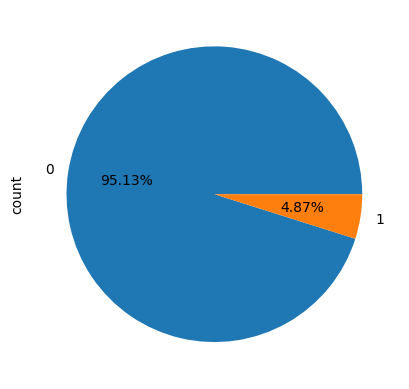

In [ ]:
import matplotlib.pyplot as plt

data = df['stroke'].value_counts()
data.plot(kind='pie',autopct='%.2f%%')
plt.show()

In [ ]:
df.isnull().sum()

,0
id,0
gender,0
age,0
hypertension,0
heart_disease,0
ever_married,0
work_type,0
Residence_type,0
avg_glucose_level,0
bmi,201


In [ ]:
 from imblearn.under_sampling import RandomUnderSampler
 from sklearn.model_selection import train_test_split
 from sklearn.preprocessing import LabelEncoder

 under_sampling = RandomUnderSampler(random_state=0)
 df_X = df.drop(['id', 'stroke'], axis=1)
 df_y = df[['stroke']]

 le = LabelEncoder()
 df_y = le.fit_transform(df_y)

 #imputation
 df_X['bmi'].fillna(df_X['bmi'].mean(), inplace=True)

 #categorical encoding
 le = LabelEncoder()
 df_X['gender'] = le.fit_transform(df_X['gender'])
 df_X['ever_married'] = le.fit_transform(df_X['ever_married'])
 df_X['work_type'] = le.fit_transform(df_X['work_type'])
 df_X['Residence_type'] = le.fit_transform(df_X['Residence_type'])
 df_X['smoking_status'] = le.fit_transform(df_X['smoking_status'])

 X = df_X.astype(float).values
 y = df_y

 X_train, X_test, y_train, y_test = train_test_split(X,y, test_size=0.25, random_state=42)

 X_resampled, y_resampled = under_sampling.fit_resample(X_train, y_train)

 print('sebelum undersampling')
 print(pd.DataFrame(y_train).value_counts())
 print('setelah undersampling')
 print(pd.DataFrame(y_resampled).value_counts())

sebelum undersampling
0
0    3663
1     169
Name: count, dtype: int64
setelah undersampling
0
0    169
1    169
Name: count, dtype: int64


/usr/local/lib/python3.12/dist-packages/sklearn/preprocessing/_label.py:110: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for example using ravel().
  y = column_or_1d(y, warn=True)
/tmp/ipython-input-4255555991.py:13: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df_X['bmi'].fillna(df_X['bmi'].mean(), inplace=True)


In [ ]:
df_X

,gender,age,hypertension,heart_disease,ever_married,work_type,Residence_type,avg_glucose_level,bmi,smoking_status
0,1,67.0,0,1,1,2,1,228.69,36.600000,1
1,0,61.0,0,0,1,3,0,202.21,28.893237,2
2,1,80.0,0,1,1,2,0,105.92,32.500000,2
3,0,49.0,0,0,1,2,1,171.23,34.400000,3
4,0,79.0,1,0,1,3,0,174.12,24.000000,2
...,...,...,...,...,...,...,...,...,...,...
5105,0,80.0,1,0,1,2,1,83.75,28.893237,2
5106,0,81.0,0,0,1,3,1,125.20,40.000000,2
5107,0,35.0,0,0,1,3,0,82.99,30.600000,2
5108,1,51.0,0,0,1,2,0,166.29,25.600000,1


In [ ]:
df_y = df[['stroke']]
df_y

,stroke
0,1
1,1
2,1
3,1
4,1
...,...
5105,0
5106,0
5107,0
5108,0


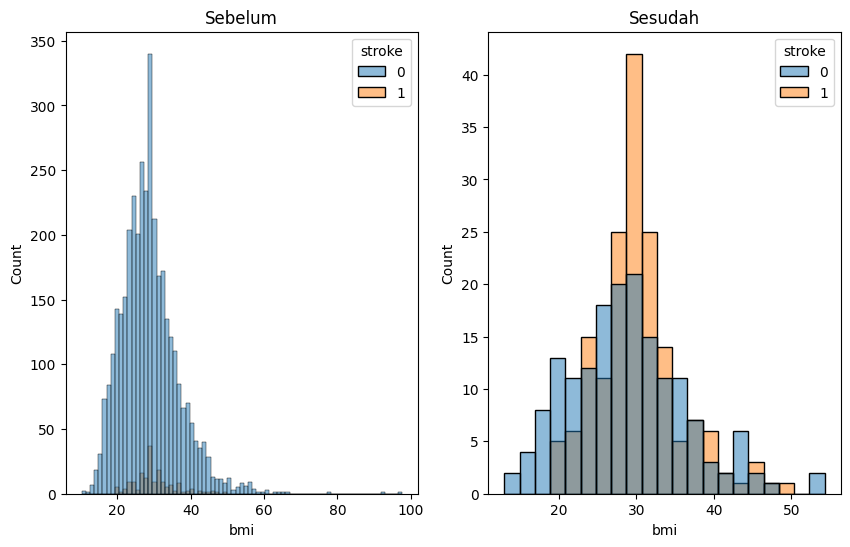

In [ ]:
from scipy.stats import norm
import seaborn as sns
import matplotlib.pyplot as plt

dfx_ori= pd.DataFrame(X_train, columns=df_X.columns)
dfy_ori = pd.DataFrame(y_train, columns=['stroke'])
df_sebelum = pd.concat([dfx_ori, dfy_ori], axis=1)

dfx_res = pd.DataFrame(X_resampled, columns=df_X.columns)
dfy_res = pd.DataFrame(y_resampled, columns=['stroke'])
df_sesudah = pd.concat([dfx_res, dfy_res], axis=1)

f, axes = plt.subplots(1,2, figsize=(10, 6))
sns.histplot(data=df_sebelum, x='bmi',hue='stroke', ax=axes[0]).set(title='Sebelum')
sns.histplot(data=df_sesudah, x='bmi',hue='stroke', ax=axes[1]).set(title='Sesudah')
plt.xticks(rotation='horizontal')

plt.show()

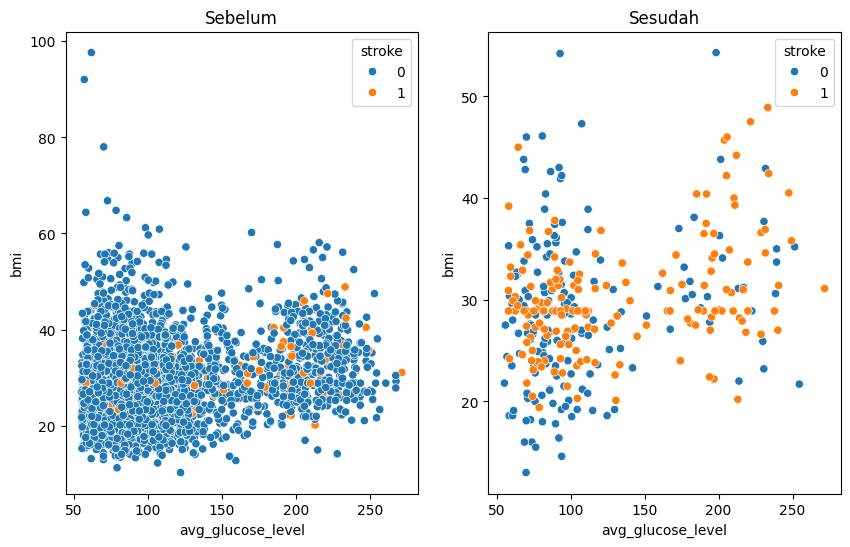

In [ ]:
import seaborn as sns

f, axes = plt.subplots(1,2, figsize=(10, 6))
sns.scatterplot(x='avg_glucose_level', y='bmi', data=df_sebelum, hue='stroke', ax=axes[0]).set(title='Sebelum')
sns.scatterplot(x='avg_glucose_level', y='bmi', data=df_sesudah, hue='stroke', ax=axes[1]).set(title='Sesudah')
plt.xticks()

plt.show()

In [ ]:
 from imblearn.over_sampling import RandomOverSampler
 from sklearn.model_selection import train_test_split
 from sklearn.preprocessing import LabelEncoder

 over_sampling = RandomOverSampler(random_state=0)
 df_X = df.drop(['id', 'stroke'], axis=1)
 df_y = df['stroke']

 #imputation
 df_X['bmi'].fillna(df_X['bmi'].mean(), inplace=True)

 #categorical encoding
 le = LabelEncoder()

 df_X['gender'] = le.fit_transform(df_X['gender'])
 df_X['ever_married'] = le.fit_transform(df_X['ever_married'])
 df_X['work_type'] = le.fit_transform(df_X['work_type'])
 df_X['Residence_type'] = le.fit_transform(df_X['Residence_type'])
 df_X['smoking_status'] = le.fit_transform(df_X['smoking_status'])

 X = df_X.astype(float).values
 y = df_y.astype(float).values

 X_train, X_test, y_train, y_test = train_test_split(X,y, test_size=0.25, random_state=42)
 X_resampled, y_resampled = over_sampling.fit_resample(X_train, y_train)

 print('sebelum random oversampling')
 print(pd.DataFrame(y_train).value_counts())

 print('setelah random oversampling')
 print(pd.DataFrame(y_resampled).value_counts())

sebelum random oversampling
0  
0.0    3663
1.0     169
Name: count, dtype: int64
setelah random oversampling
0  
0.0    3663
1.0    3663
Name: count, dtype: int64


/tmp/ipython-input-3127705144.py:10: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df_X['bmi'].fillna(df_X['bmi'].mean(), inplace=True)


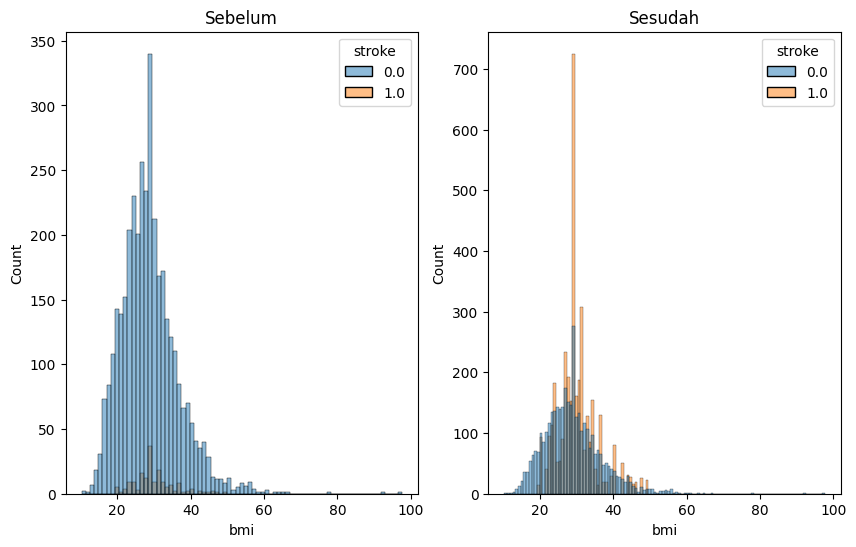

In [ ]:
from scipy.stats import norm
import seaborn as sns
import matplotlib.pyplot as plt

dfx_ori= pd.DataFrame(X_train, columns=df_X.columns)
dfy_ori = pd.DataFrame(y_train, columns=['stroke'])
df_sebelum = pd.concat([dfx_ori, dfy_ori], axis=1)

dfx_res = pd.DataFrame(X_resampled, columns=df_X.columns)
dfy_res = pd.DataFrame(y_resampled, columns=['stroke'])
df_sesudah = pd.concat([dfx_res, dfy_res], axis=1)

f, axes = plt.subplots(1,2, figsize=(10, 6))
sns.histplot(data=df_sebelum, x='bmi',hue='stroke', ax=axes[0]).set(title='Sebelum')
sns.histplot(data=df_sesudah, x='bmi',hue='stroke', ax=axes[1]).set(title='Sesudah')
plt.xticks()

plt.show()

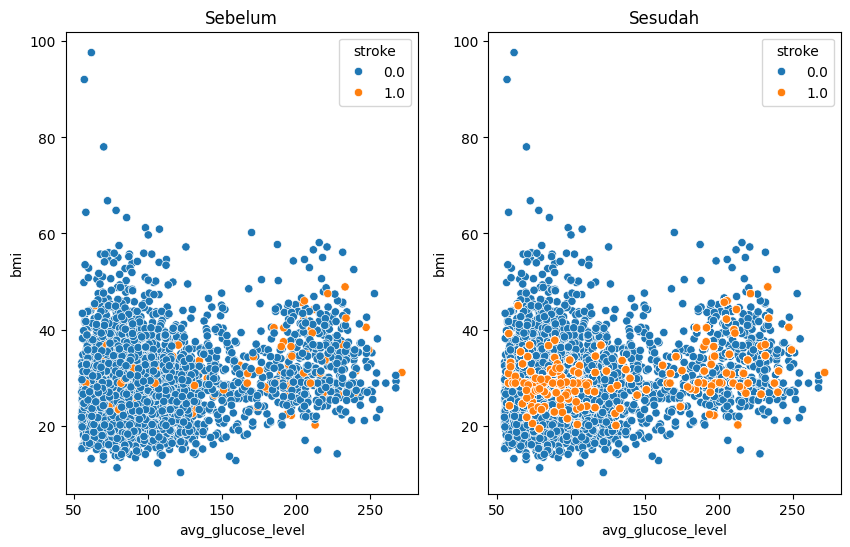

In [ ]:
import seaborn as sns

f, axes = plt.subplots(1,2, figsize=(10, 6))
sns.scatterplot(x='avg_glucose_level', y='bmi', data=df_sebelum, hue='stroke', ax=axes[0]).set(title='Sebelum')
sns.scatterplot(x='avg_glucose_level', y='bmi', data=df_sesudah, hue='stroke', ax=axes[1]).set(title='Sesudah')
plt.xticks()

plt.show()

In [ ]:
from imblearn.over_sampling import SMOTE
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder

df_X = df.drop(['id','stroke'],axis=1)
df_y = df['stroke']

#imputation
df_X['bmi'].fillna(df_X['bmi'].mean(), inplace=True)

#categorical encoding
le = LabelEncoder()
df_X['gender'] = le.fit_transform(df_X['gender'])
df_X['ever_married'] = le.fit_transform(df_X['ever_married'])
df_X['work_type'] = le.fit_transform(df_X['work_type'])
df_X['Residence_type'] = le.fit_transform(df_X['Residence_type'])
df_X['smoking_status'] = le.fit_transform(df_X['smoking_status'])

X = df_X.astype(float).values
y = df_y.astype(float).values
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=42)
smote = SMOTE(random_state=0)
X_resampled, y_resampled = smote.fit_resample(X_train, y_train)

print('Sebelum SMOTE')
print(pd.DataFrame(y_train).value_counts())
print('Setelah SMOTE')
print(pd.DataFrame(y_resampled).value_counts())

Sebelum SMOTE
0  
0.0    3663
1.0     169
Name: count, dtype: int64
Setelah SMOTE
0  
0.0    3663
1.0    3663
Name: count, dtype: int64


/tmp/ipython-input-773218237.py:9: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df_X['bmi'].fillna(df_X['bmi'].mean(), inplace=True)


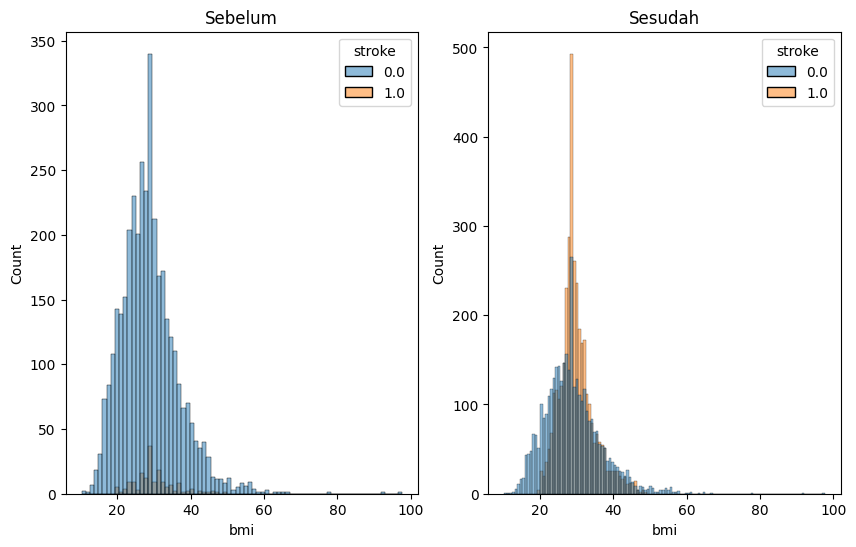

In [ ]:
 from scipy.stats import norm
 import seaborn as sns
 import matplotlib.pyplot as plt

 dfx_ori= pd.DataFrame(X_train, columns=df_X.columns)
 dfy_ori = pd.DataFrame(y_train, columns=['stroke'])
 df_sebelum = pd.concat([dfx_ori, dfy_ori], axis=1)

 dfx_res = pd.DataFrame(X_resampled, columns=df_X.columns)
 dfy_res = pd.DataFrame(y_resampled, columns=['stroke'])
 df_sesudah = pd.concat([dfx_res, dfy_res], axis=1)

 f, axes = plt.subplots(1,2, figsize=(10, 6))
 sns.histplot(data=df_sebelum, x='bmi',hue='stroke', ax=axes[0]).set(title='Sebelum')
 sns.histplot(data=df_sesudah, x='bmi',hue='stroke', ax=axes[1]).set(title='Sesudah')
 plt.xticks()

 plt.show()

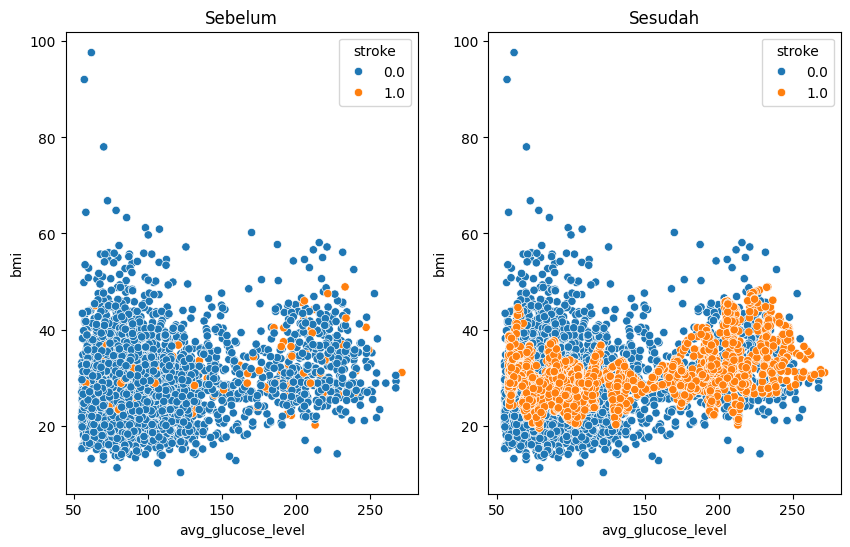

In [ ]:
import seaborn as sns

f, axes = plt.subplots(1,2, figsize=(10, 6))
sns.scatterplot(x='avg_glucose_level', y='bmi', data=df_sebelum, hue='stroke', ax=axes[0]).set(title='Sebelum')
sns.scatterplot(x='avg_glucose_level', y='bmi', data=df_sesudah, hue='stroke', ax=axes[1]).set(title='Sesudah')
plt.xticks()

plt.show()

In [ ]:
from imblearn.over_sampling import ADASYN
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder

df_X = df.drop(['id','stroke'],axis=1)
df_y = df['stroke']

#imputation
df_X['bmi'].fillna(df_X['bmi'].mean(), inplace=True)

#categorical encoding
le = LabelEncoder()
df_X['gender'] = le.fit_transform(df_X['gender'])
df_X['ever_married'] = le.fit_transform(df_X['ever_married'])
df_X['work_type'] = le.fit_transform(df_X['work_type'])
df_X['Residence_type'] = le.fit_transform(df_X['Residence_type'])
df_X['smoking_status'] = le.fit_transform(df_X['smoking_status'])

X = df_X.astype(float).values
y = df_y.astype(float).values
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=42)
adasyn = ADASYN(random_state=0)
X_resampled, y_resampled = adasyn.fit_resample(X_train, y_train)

print('Sebelum ADASYN')
print(pd.DataFrame(y_train).value_counts())

print('Setelah ADASYIN')
print(pd.DataFrame(y_resampled).value_counts())

Sebelum ADASYN
0  
0.0    3663
1.0     169
Name: count, dtype: int64
Setelah ADASYIN
0  
1.0    3676
0.0    3663
Name: count, dtype: int64


/tmp/ipython-input-2077449474.py:9: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df_X['bmi'].fillna(df_X['bmi'].mean(), inplace=True)


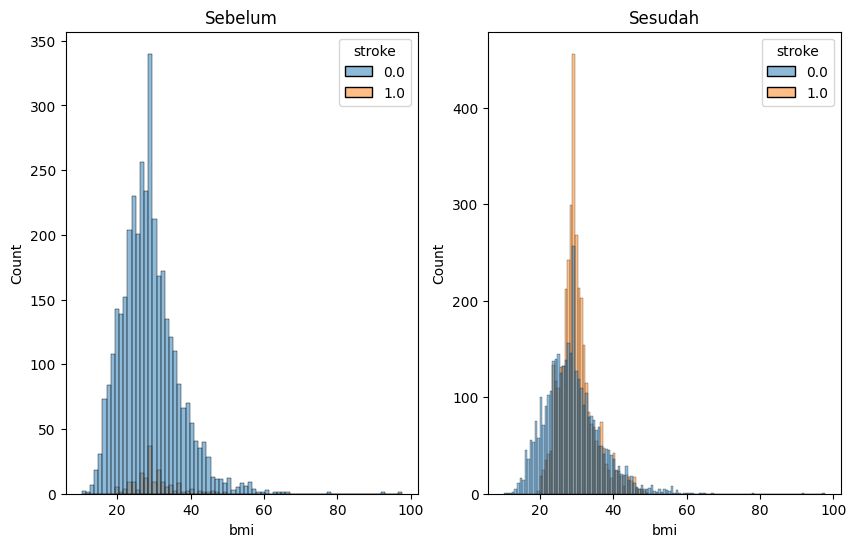

In [ ]:
 from scipy.stats import norm
 import seaborn as sns
 import matplotlib.pyplot as plt

 dfx_ori= pd.DataFrame(X_train, columns=df_X.columns)
 dfy_ori = pd.DataFrame(y_train, columns=['stroke'])
 df_sebelum = pd.concat([dfx_ori, dfy_ori], axis=1)

 dfx_res = pd.DataFrame(X_resampled, columns=df_X.columns)
 dfy_res = pd.DataFrame(y_resampled, columns=['stroke'])
 df_sesudah = pd.concat([dfx_res, dfy_res], axis=1)

 f, axes = plt.subplots(1,2, figsize=(10, 6))
 sns.histplot(data=df_sebelum, x='bmi',hue='stroke', ax=axes[0]).set(title='Sebelum')
 sns.histplot(data=df_sesudah, x='bmi',hue='stroke', ax=axes[1]).set(title='Sesudah')
 plt.xticks()

 plt.show()

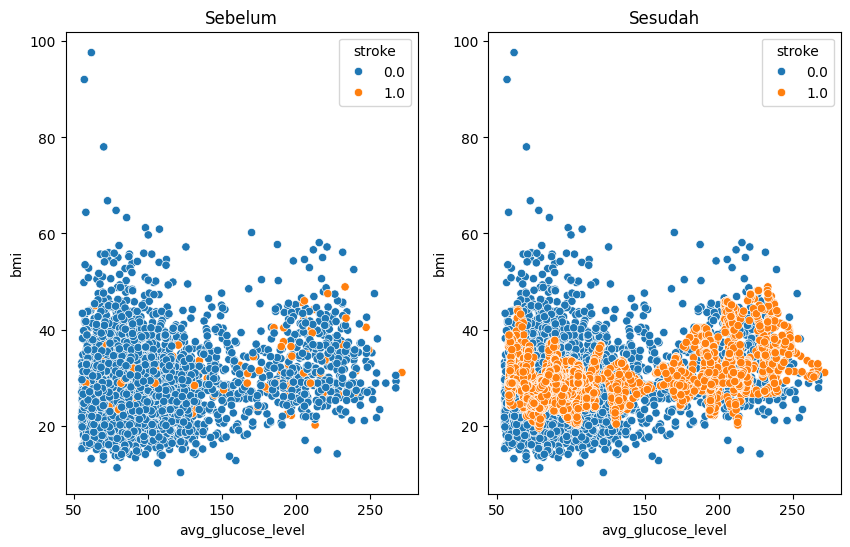

In [ ]:
 import seaborn as sns

 f, axes = plt.subplots(1,2, figsize=(10, 6))
 sns.scatterplot(x='avg_glucose_level', y='bmi', data=df_sebelum, hue='stroke', ax=axes[0]).set(title='Sebelum')
 sns.scatterplot(x='avg_glucose_level', y='bmi', data=df_sesudah, hue='stroke', ax=axes[1]).set(title='Sesudah')
 plt.xticks()

 plt.show()

In [ ]:
from google.colab import drive
import pandas as pd

drive.mount('/content/drive')
file_path = '/content/drive/MyDrive/Semester 5/Praktikum Penambangan Data/Pertemuan 9/healthcare-dataset-stroke-data.csv'

try:
    df = pd.read_csv(file_path)
    print("Dataset berhasil dimuat!")
except FileNotFoundError:
    print("File tidak ditemukan")

df.head()

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Dataset berhasil dimuat!


,id,gender,age,hypertension,heart_disease,ever_married,work_type,Residence_type,avg_glucose_level,bmi,smoking_status,stroke
0,9046,Male,67.0,0,1,Yes,Private,Urban,228.69,36.6,formerly smoked,1
1,51676,Female,61.0,0,0,Yes,Self-employed,Rural,202.21,NaN,never smoked,1
2,31112,Male,80.0,0,1,Yes,Private,Rural,105.92,32.5,never smoked,1
3,60182,Female,49.0,0,0,Yes,Private,Urban,171.23,34.4,smokes,1
4,1665,Female,79.0,1,0,Yes,Self-employed,Rural,174.12,24.0,never smoked,1


In [ ]:
from google.colab import drive
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, confusion_matrix
from imblearn.over_sampling import SMOTE

drive.mount('/content/drive')

file_path = '/content/drive/MyDrive/Semester 5/Praktikum Penambangan Data/Pertemuan 9/Churn_Modelling.csv'

try:
    df = pd.read_csv(file_path)
    print("Dataset Churn Modelling berhasil dimuat!")
    display(df.head())
except FileNotFoundError:
    print("File tidak ditemukan. Pastikan sudah di-upload ke folder yang benar.")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Dataset Churn Modelling berhasil dimuat!


,RowNumber,CustomerId,Surname,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
0,1,15634602,Hargrave,619,France,Female,42,2,0.00,1,1,1,101348.88,1
1,2,15647311,Hill,608,Spain,Female,41,1,83807.86,1,0,1,112542.58,0
2,3,15619304,Onio,502,France,Female,42,8,159660.80,3,1,0,113931.57,1
3,4,15701354,Boni,699,France,Female,39,1,0.00,2,0,0,93826.63,0
4,5,15737888,Mitchell,850,Spain,Female,43,2,125510.82,1,1,1,79084.10,0


In [ ]:
df_clean = df.drop(['RowNumber', 'CustomerId', 'Surname'], axis=1)

le = LabelEncoder()
df_clean['Geography'] = le.fit_transform(df_clean['Geography'])
df_clean['Gender'] = le.fit_transform(df_clean['Gender'])

X = df_clean.drop('Exited', axis=1)  # Target: 1 = Churn (Keluar), 0 = Stay
y = df_clean['Exited']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=42)

# Cek ketimpangan data pada Training Set
print("Jumlah sampel per kelas di Training Set (Sebelum SMOTE):")
print(y_train.value_counts())

Jumlah sampel per kelas di Training Set (Sebelum SMOTE):
Exited
0    5960
1    1540
Name: count, dtype: int64


In [ ]:
print("=== PERFORMA MODEL SEBELUM BALANCING ===")

rf_ori = RandomForestClassifier(random_state=42)
rf_ori.fit(X_train, y_train)

# Prediksi ke Data Test
y_pred_ori = rf_ori.predict(X_test)

# Tampilkan Laporan Klasifikasi
print(classification_report(y_test, y_pred_ori))

=== PERFORMA MODEL SEBELUM BALANCING ===
              precision    recall  f1-score   support

           0       0.88      0.97      0.92      2003
           1       0.77      0.47      0.59       497

    accuracy                           0.87      2500
   macro avg       0.83      0.72      0.75      2500
weighted avg       0.86      0.87      0.86      2500



In [ ]:
# Inisialisasi SMOTE
smote = SMOTE(random_state=42)

# Terapkan SMOTE pada data training
X_train_smote, y_train_smote = smote.fit_resample(X_train, y_train)

print("Jumlah sampel per kelas di Training Set (Setelah SMOTE):")
print(y_train_smote.value_counts())

Jumlah sampel per kelas di Training Set (Setelah SMOTE):
Exited
1    5960
0    5960
Name: count, dtype: int64


In [ ]:
print("=== PERFORMA MODEL SETELAH SMOTE ===")

# Inisialisasi dan Latih Model Baru
rf_smote = RandomForestClassifier(random_state=42)
rf_smote.fit(X_train_smote, y_train_smote)

# Prediksi ke Data Test
y_pred_smote = rf_smote.predict(X_test)

# Tampilkan Laporan Klasifikasi
print(classification_report(y_test, y_pred_smote))

=== PERFORMA MODEL SETELAH SMOTE ===
              precision    recall  f1-score   support

           0       0.91      0.87      0.89      2003
           1       0.55      0.65      0.60       497

    accuracy                           0.83      2500
   macro avg       0.73      0.76      0.74      2500
weighted avg       0.84      0.83      0.83      2500



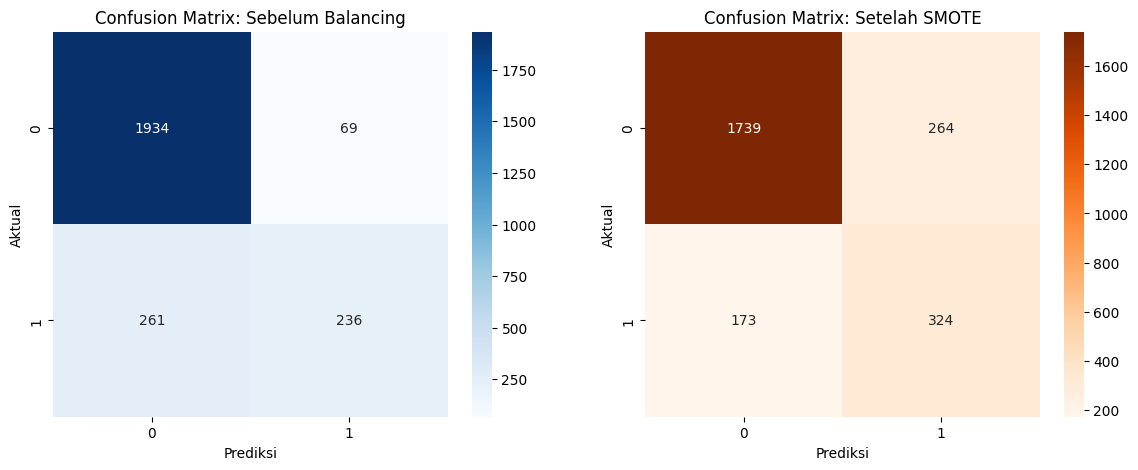

In [ ]:
fig, ax = plt.subplots(1, 2, figsize=(14, 5))

# Visualisasi Sebelum SMOTE
sns.heatmap(confusion_matrix(y_test, y_pred_ori), annot=True, fmt='d', cmap='Blues', ax=ax[0])
ax[0].set_title('Confusion Matrix: Sebelum Balancing')
ax[0].set_xlabel('Prediksi')
ax[0].set_ylabel('Aktual')

# Visualisasi Setelah SMOTE
sns.heatmap(confusion_matrix(y_test, y_pred_smote), annot=True, fmt='d', cmap='Oranges', ax=ax[1])
ax[1].set_title('Confusion Matrix: Setelah SMOTE')
ax[1].set_xlabel('Prediksi')
ax[1].set_ylabel('Aktual')

plt.show()